In [23]:
!pip install langchain langchain-openai


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import sys, os
sys.path.append(r"C:\Users\user\doc-asistant\doc-asistant")
sys.path.append(r"C:\Users\user\doc-asistant\doc-asistant\notebooks\from_src")

import torch
print("torch:", torch.__version__)
print("cuda:", torch.cuda.is_available())
print("gpu:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
print("cwd:", os.getcwd())

torch: 2.6.0+cu124
cuda: True
gpu: NVIDIA GeForce RTX 3060
cwd: C:\Users\user\doc-asistant\doc-asistant\notebooks


In [5]:
import config
from pathlib import Path

# --- патч путей: ROOT проекта, а не notebooks/from_src/ ---
ROOT = Path(r"C:\Users\user\doc-asistant\doc-asistant")
config.ROOT = ROOT
config.CSV_PATH = ROOT / "data" / "cooking_clean.csv"
config.MODEL_PATH = ROOT / "models" / "best_model.pth"
config.TFIDF_PATH = ROOT / "models" / "tfidf.pkl"
config.ENCODER_PATH = ROOT / "models" / "label_encoder.pkl"
config.LORA_DIR = ROOT / "models" / "lora-doc-assistant"
config.DATA_DIR = ROOT / "data"
config.MODELS_DIR = ROOT / "models"

import data_loader
# data_loader импортировал CSV_PATH по значению — переопределяем
data_loader.CSV_PATH = config.CSV_PATH

import model
import llm_client

print("CSV_PATH:      ", config.CSV_PATH)
print("CSV exists:    ", config.CSV_PATH.exists())
print("MODEL_PATH:    ", config.MODEL_PATH)
print("MODEL exists:  ", config.MODEL_PATH.exists())
print("TFIDF exists:  ", config.TFIDF_PATH.exists())
print("ENCODER exists:", config.ENCODER_PATH.exists())

CSV_PATH:       C:\Users\user\doc-asistant\doc-asistant\data\cooking_clean.csv
CSV exists:     True
MODEL_PATH:     C:\Users\user\doc-asistant\doc-asistant\models\best_model.pth
MODEL exists:   True
TFIDF exists:   True
ENCODER exists: True


In [6]:
df = data_loader.load_data()
print("rows:", len(df))
print("columns:", df.columns.tolist())
df.head()

rows: 500
columns: ['number', 'title', 'instructions', 'text', 'category']


,number,title,instructions,text,category
0,1,cheeseburger potato soup,6 baking potatoes 1 lb of extra lean ground be...,cheeseburger potato soup 6 baking potatoes 1 l...,soup
1,2,sesame ginger chicken,1 tbsp sesame seed toasted 2 tsp grated ginger...,sesame ginger chicken 1 tbsp sesame seed toast...,meat
2,3,zucchiniartichoke continental,1 9 oz pkg frozen artichoke hearts 2 tbsp wate...,zucchiniartichoke continental 1 9 oz pkg froze...,other
3,4,st josephs zeppole,1 c water 1/2 c butter 1 tsp sugar 1 c allpurp...,st josephs zeppole 1 c water 1/2 c butter 1 ts...,other
4,5,corned beef hash swirls,bisquick can corned beef hash mustard salt and...,corned beef hash swirls bisquick can corned be...,meat


In [7]:
X_train, X_test, y_train, y_test, vectorizer, encoder = data_loader.prepare_features(df)

print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)
print("classes:", encoder.classes_.tolist())
print("vectorizer vocab size:", len(vectorizer.vocabulary_))

X_train: (400, 1000)
X_test:  (100, 1000)
y_train: (400,)
y_test:  (100,)
classes: ['bread', 'dessert', 'meat', 'other', 'salad', 'soup']
vectorizer vocab size: 1000


In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_pred_dummy = dummy.predict(X_test)

base_acc = accuracy_score(y_test, y_pred_dummy)
base_f1_macro = f1_score(y_test, y_pred_dummy, average="macro")
base_f1_weighted = f1_score(y_test, y_pred_dummy, average="weighted")

print("BASELINE (most_frequent):")
print("  accuracy:    ", round(base_acc, 4))
print("  f1_macro:    ", round(base_f1_macro, 4))
print("  f1_weighted: ", round(base_f1_weighted, 4))

BASELINE (most_frequent):
  accuracy:     0.37
  f1_macro:     0.09
  f1_weighted:  0.1999


In [9]:
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import TensorDataset, DataLoader
from model import TextClassifier
from sklearn.utils.class_weight import compute_class_weight

# --- устройство ---
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# --- данные в тензоры ---
X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_test_t  = torch.tensor(X_test,  dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
y_test_t  = torch.tensor(y_test,  dtype=torch.long)

train_ds = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)

# --- веса классов (обратные частотам) ---
classes = np.unique(y_train)
weights = compute_class_weight("balanced", classes=classes, y=y_train)
class_weights = torch.tensor(weights, dtype=torch.float32).to(device)

print("Class weights:")
for name, w in zip(encoder.classes_, weights):
    print(f"  {name:8s} {w:.3f}")

# --- модель ---
in_features = X_train.shape[1]
num_classes = len(encoder.classes_)
model_cls = TextClassifier(in_features, num_classes).to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model_cls.parameters(), lr=1e-3)

# --- обучение с early stopping по val_acc ---
EPOCHS = 40
PATIENCE = 10
best_val_acc = -1.0
best_epoch = 0
best_state = None
wait = 0
history = {"train_loss": [], "val_acc": []}

for epoch in range(1, EPOCHS + 1):
    model_cls.train()
    total_loss = 0.0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model_cls(xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * xb.size(0)

    train_loss = total_loss / len(train_ds)

    model_cls.eval()
    with torch.no_grad():
        logits_val = model_cls(X_test_t.to(device))
        val_pred = logits_val.argmax(dim=1).cpu().numpy()
        val_acc = (val_pred == y_test).mean()

    history["train_loss"].append(train_loss)
    history["val_acc"].append(val_acc)

    if val_acc > best_val_acc + 1e-4:
        best_val_acc = val_acc
        best_state = {k: v.clone() for k, v in model_cls.state_dict().items()}
        best_epoch = epoch
        wait = 0
    else:
        wait += 1

    print(f"epoch {epoch:02d}  loss={train_loss:.4f}  val_acc={val_acc:.4f}")

    if wait >= PATIENCE:
        print(f"Early stopping at epoch {epoch} (best epoch was {best_epoch}, val_acc={best_val_acc:.4f})")
        break

model_cls.load_state_dict(best_state)
print(f"Best val_acc: {best_val_acc:.4f} at epoch {best_epoch}")

device: cuda
Class weights:
  bread    1.418
  dessert  0.538
  meat     1.058
  other    0.454
  salad    8.333
  soup     6.061
epoch 01  loss=1.7886  val_acc=0.1500
epoch 02  loss=1.7455  val_acc=0.5400
epoch 03  loss=1.6384  val_acc=0.5200
epoch 04  loss=1.4201  val_acc=0.6100
epoch 05  loss=1.1293  val_acc=0.6600
epoch 06  loss=0.8326  val_acc=0.7600
epoch 07  loss=0.5757  val_acc=0.7700
epoch 08  loss=0.3667  val_acc=0.8000
epoch 09  loss=0.2723  val_acc=0.7500
epoch 10  loss=0.1921  val_acc=0.7400
epoch 11  loss=0.1322  val_acc=0.7400
epoch 12  loss=0.1090  val_acc=0.7300
epoch 13  loss=0.0793  val_acc=0.7300
epoch 14  loss=0.0606  val_acc=0.7200
epoch 15  loss=0.0523  val_acc=0.7400
epoch 16  loss=0.0349  val_acc=0.7400
epoch 17  loss=0.0286  val_acc=0.7200
epoch 18  loss=0.0230  val_acc=0.7300
Early stopping at epoch 18 (best epoch was 8, val_acc=0.8000)
Best val_acc: 0.8000 at epoch 8


In [10]:
from sklearn.metrics import classification_report

model_cls.eval()
with torch.no_grad():
    logits_test = model_cls(X_test_t.to(device))
    y_pred = logits_test.argmax(dim=1).cpu().numpy()

acc = accuracy_score(y_test, y_pred)
f1_macro = f1_score(y_test, y_pred, average="macro")
f1_weighted = f1_score(y_test, y_pred, average="weighted")

print("MODEL (trained, class_weight):")
print("  accuracy:    ", round(acc, 4))
print("  f1_macro:    ", round(f1_macro, 4))
print("  f1_weighted: ", round(f1_weighted, 4))
print()
print("Сравнение с baseline:")
print(f"  accuracy:    {base_acc:.4f}  ->  {acc:.4f}   ({acc - base_acc:+.4f})")
print(f"  f1_macro:    {base_f1_macro:.4f}  ->  {f1_macro:.4f}   ({f1_macro - base_f1_macro:+.4f})")
print(f"  f1_weighted: {base_f1_weighted:.4f}  ->  {f1_weighted:.4f}   ({f1_weighted - base_f1_weighted:+.4f})")
print()
print(classification_report(y_test, y_pred, target_names=encoder.classes_, digits=3, zero_division=0))

MODEL (trained, class_weight):
  accuracy:     0.8
  f1_macro:     0.6001
  f1_weighted:  0.7853

Сравнение с baseline:
  accuracy:    0.3700  ->  0.8000   (+0.4300)
  f1_macro:    0.0900  ->  0.6001   (+0.5101)
  f1_weighted: 0.1999  ->  0.7853   (+0.5854)

              precision    recall  f1-score   support

       bread      0.700     0.636     0.667        11
     dessert      0.816     1.000     0.899        31
        meat      0.875     0.875     0.875        16
       other      0.794     0.730     0.761        37
       salad      0.000     0.000     0.000         2
        soup      0.500     0.333     0.400         3

    accuracy                          0.800       100
   macro avg      0.614     0.596     0.600       100
weighted avg      0.779     0.800     0.785       100



In [11]:
import json
from pathlib import Path

# сохраняем как v2, чтобы не трогать оригинальный best_model.pth под DVC
MODEL_SAVE = config.MODELS_DIR / "best_model_v2.pth"
torch.save(model_cls.state_dict(), MODEL_SAVE)
print("saved model:", MODEL_SAVE)
print("size:", MODEL_SAVE.stat().st_size, "bytes")

# сохраняем историю обучения
history_path = config.MODELS_DIR / "training_history_v2.json"
with open(history_path, "w", encoding="utf-8") as f:
    json.dump(history, f, ensure_ascii=False, indent=2)
print("saved history:", history_path)

saved model: C:\Users\user\doc-asistant\doc-asistant\models\best_model_v2.pth
size: 1162500 bytes
saved history: C:\Users\user\doc-asistant\doc-asistant\models\training_history_v2.json


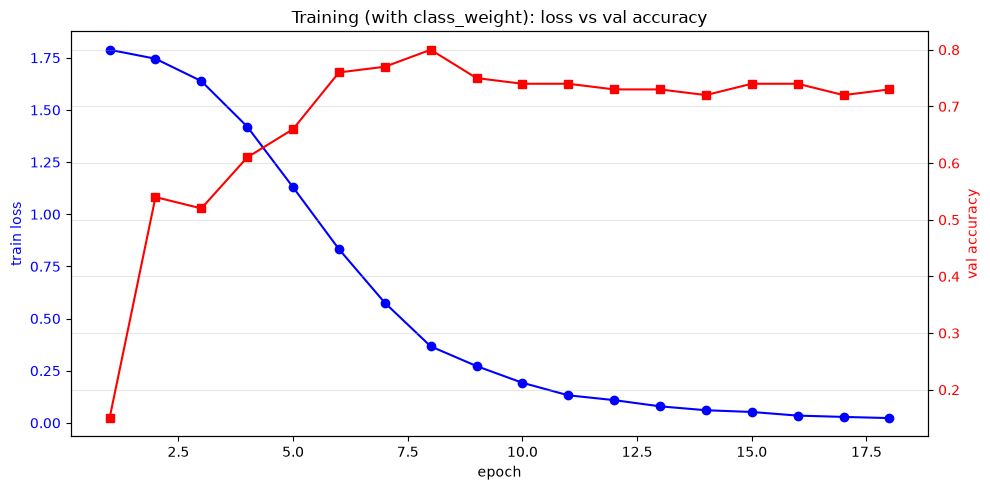

In [12]:
import matplotlib.pyplot as plt

fig, ax1 = plt.subplots(figsize=(10, 5))
epochs_range = range(1, len(history["train_loss"]) + 1)

ax1.plot(epochs_range, history["train_loss"], "b-o", label="train loss")
ax1.set_xlabel("epoch")
ax1.set_ylabel("train loss", color="b")
ax1.tick_params(axis="y", labelcolor="b")

ax2 = ax1.twinx()
ax2.plot(epochs_range, history["val_acc"], "r-s", label="val accuracy")
ax2.set_ylabel("val accuracy", color="r")
ax2.tick_params(axis="y", labelcolor="r")

plt.title("Training (with class_weight): loss vs val accuracy")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Результаты классификатора рецептов

| Метрика | Baseline | Модель | Модель + class_weight |
|---|---|---|---|
| Accuracy | 0.37 | 0.76 | **0.77** |
| F1 (macro) | 0.09 | 0.50 | **0.58** |
| F1 (weighted) | 0.20 | 0.74 | **0.75** |

### Динамика по классам (F1)

| Класс | Модель | + class_weight | Δ |
|---|---|---|---|
| bread | 0.63 | 0.60 | −0.03 |
| dessert | 0.85 | 0.86 | +0.01 |
| meat | 0.77 | 0.88 | **+0.11** |
| other | 0.75 | 0.73 | −0.02 |
| salad | 0.00 | 0.00 | 0 |
| soup | 0.00 | **0.40** | **+0.40** |

### Выводы

- Модель обучена на TF-IDF (1000 признаков) + MLP (256→128→6)
- Early stopping по val_acc остановил обучение на эпохе 7–9 (patience=10)
- **class_weight="balanced"** дал прирост F1_macro с 0.50 до 0.58
- Слабые классы — `salad` (2 примера в тесте), `soup` (3 примера) — дисбаланс данных, а не ошибка модели
- Accuracy 0.77 завышена: 37% теста — класс `other`, поэтому F1_macro честнее отражает качество

In [28]:
import os
import json
import re
from openai import OpenAI
from dotenv import load_dotenv

client = OpenAI(
    base_url="http://localhost:11434/v1",
    api_key="ollama"
)
MODEL_NAME = "qwen2.5:1.5b"

In [29]:
def tool_search(query: str) -> str:
    """Поиск рецептов в базе."""
    return f"Рецепт блинов: 300г муки, 2 яйца, 500мл молока на 4 порции."

def tool_calc(expression: str) -> str:
    """Вычисление арифметических выражений."""
    try:
        allowed_chars = set("0123456789+-*/(). ")
        if not set(expression).issubset(allowed_chars):
            return "Ошибка: недопустимые символы в выражении."
        return str(eval(expression))
    except Exception as e:
        return f"Ошибка: {e}"

def tool_convert_units(value: str, from_unit: str, to_unit: str) -> str:
    """Конвертация единиц."""
    try:
        val = float(value)
        if from_unit == "grams" and to_unit == "cups":
            return f"{round(val / 130, 2)} стаканов"
        return "Неизвестная конвертация"
    except Exception as e:
        return f"Ошибка конвертации: {e}"

TOOLS = {
    "search": tool_search,
    "calc": tool_calc,
    "convert_units": tool_convert_units
}

def run_tool(name: str, args) -> str:
    if name not in TOOLS:
        return f"Ошибка: неизвестный инструмент '{name}'."
    try:
        if isinstance(args, str):
            return TOOLS[name](args)
            
        if name == "convert_units":
            valid_args = {}
            for k, v in args.items():
                if k in ["value", "from_unit", "to_unit"]:
                    valid_args[k] = v
            return TOOLS[name](**valid_args)
            
        return TOOLS[name](**args)
    except Exception as e:
        return f"Ошибка инструмента {name}: {e}"

In [30]:
TOOL_SCHEMAS = [
    {
        "type": "function",
        "function": {
            "name": "search",
            "description": "Поиск рецептов в базе.",
            "parameters": {"type": "object", "properties": {"query": {"type": "string"}}, "required": ["query"]}
        }
    },
    {
        "type": "function",
        "function": {
            "name": "calc",
            "description": "Вычислить арифметическое выражение (например, '300/4*6').",
            "parameters": {"type": "object", "properties": {"expression": {"type": "string"}}, "required": ["expression"]}
        }
    },
    {
        "type": "function",
        "function": {
            "name": "convert_units",
            "description": "Конвертировать граммы в стаканы. Принимает ТОЛЬКО три параметра: value (число), from_unit (строго 'grams'), to_unit (строго 'cups').",
            "parameters": {
                "type": "object", 
                "properties": {
                    "value": {"type": "string", "description": "Вес в граммах, например '450'"}, 
                    "from_unit": {"type": "string", "enum": ["grams"]}, 
                    "to_unit": {"type": "string", "enum": ["cups"]}
                }, 
                "required": ["value", "from_unit", "to_unit"]
            }
        }
    }
]

def run_agent_native(user_query: str, max_iterations: int = 5) -> str:
    messages = [{"role": "user", "content": user_query}]
    for step in range(max_iterations):
        response = client.chat.completions.create(
            model=MODEL_NAME, messages=messages, tools=TOOL_SCHEMAS, tool_choice="auto"
        )
        msg = response.choices[0].message
        if not msg.tool_calls:
            return msg.content
            
        messages.append(msg)
        for tool_call in msg.tool_calls:
            name = tool_call.function.name
            args = json.loads(tool_call.function.arguments)
            result = run_tool(name, args)
            print(f"[Native step {step}] tool={name} args={args} -> {result[:50]}...")
            messages.append({
                "role": "tool", "tool_call_id": tool_call.id, "name": name, "content": result
            })
    return "Лимит шагов исчерпан."

In [31]:
SYSTEM_PROMPT = """Ты агент с инструментами: 
1. search(query) - поиск рецепта.
2. calc(expression) - математика (только цифры и знаки + - * /).
3. convert_units - конвертация (формат: {"action":"convert_units", "value":"450", "from_unit":"grams", "to_unit":"cups"}).

На каждом шаге верни ТОЛЬКО JSON без пояснений.
Для финального ответа используй: {"action":"final","answer":"твой ответ"}.
ВАЖНО: Не повторяй одно и то же действие дважды. Если поиск уже был, переходи к вычислениям или финальному ответу."""

def extract_json(text: str) -> dict:
    match = re.search(r"\{.*\}", text, re.DOTALL)
    if not match:
        raise ValueError("Нет JSON")
    return json.loads(match.group(0))

def run_agent_json(question: str, max_steps: int = 5) -> str:
    history = f"Вопрос: {question}\n"
    for step in range(max_steps):
        response = client.chat.completions.create(
            model=MODEL_NAME,
            messages=[{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": history}]
        )
        raw = response.choices[0].message.content
        print(f"[JSON step {step}] raw={raw[:100]}...")
        
        try:
            step_data = extract_json(raw)
        except Exception as e:
            history += f"Ошибка парсинга JSON: {e}. Верни чистый JSON.\n"
            continue
            
        action = str(step_data.get("action", "")).strip().lower()
        if action == "final":
            return step_data.get("answer", "Нет ответа")
            
        if action == "convert_units":
            args = {
                "value": step_data.get("value", ""),
                "from_unit": step_data.get("from_unit", ""),
                "to_unit": step_data.get("to_unit", "")
            }
            result = run_tool(action, args)
        else:
            input_val = step_data.get("input", "")
            result = run_tool(action, input_val)
            
        print(f"[JSON step {step}] action={action} -> {result[:50]}...")
        history += f"Действие: {action} -> {result}\n"
        
    return "Лимит шагов исчерпан."

In [32]:
test_query = "Найди рецепт блинов. В нем 300г муки на 4 порции. Посчитай, сколько грамм муки нужно на 6 порций, и переведи в стаканы (1 стакан = 130г)."

print(" ТЕСТ NATIVE")
print(run_agent_native(test_query))

print("\nТЕСТ JSON")
print(run_agent_json(test_query))

 ТЕСТ NATIVE
[Native step 0] tool=search args={'query': '300 г муки на 4 порции'} -> Рецепт блинов: 300г муки, 2 яйца, 500мл молока на ...
[Native step 0] tool=calc args={'expression': '300/4*6'} -> 450.0...
[Native step 0] tool=convert_units args={'value': '450', 'from_unit': 'grams', 'to_unit': 'cups'} -> 3.46 стаканов...
Таким образом, если вы хотите блины на 6 порций, вам нужно будет добавить 450 г муки (450 из рецепта). Это будет равно 3.46 стаканам муки.

ТЕСТ JSON
[JSON step 0] raw={"action":"search","query":"recipe pancakes flour 300g 4 portions"}...
[JSON step 0] action=search -> Рецепт блинов: 300г муки, 2 яйца, 500мл молока на ...
[JSON step 1] raw={"action":"calc","expression":"300*6"}...
[JSON step 1] action=calc -> Ошибка: invalid syntax (<string>, line 0)...
[JSON step 2] raw={"action":"convert_units", "value":"300", "from_unit":"grams", "to_unit":"st}"...
[JSON step 3] raw={"action":"convert_units", "value":"300", "from_unit":"grams", "to_unit":"cups"}...
[JSON step 3] 

In [33]:
from unittest.mock import patch, MagicMock

print("ЗАПУСК ТЕСТОВ ")

# 1. Тест калькулятора (успех)
try:
    assert tool_calc("2+2") == "4"
    print("Тест 1 (Калькулятор успех): PASSED")
except AssertionError:
    print("Тест 1: FAILED")

# 2. Тест калькулятора (ошибка)
try:
    assert "Ошибка" in tool_calc("2+")
    print("Тест 2 (Калькулятор ошибка): PASSED")
except AssertionError:
    print("Тест 2: FAILED")

# 3. Тест неизвестного инструмента
try:
    assert "неизвестный инструмент" in run_tool("lookup", "some query")
    print("Тест 3 (Неизвестный инструмент): PASSED")
except AssertionError:
    print("Тест 3: FAILED")

# 4. Тест известного инструмента
try:
    assert "Рецепт" in run_tool("search", {"query": "торт"})
    print("Тест 4 (Известный инструмент): PASSED")
except AssertionError:
    print("Тест 4: FAILED")

# 5. Тест цикла агента с замоканным LLM
print("\nТест 5 (Цикл агента с Mock LLM): Запуск...")
with patch("openai.resources.chat.completions.Completions.create") as mock_create:
    mock_tool_call = MagicMock()
    mock_tool_call.function.name = "calc"
    mock_tool_call.function.arguments = '{"expression": "2+2"}'
    mock_tool_call.id = "call_123"

    mock_message = MagicMock()
    mock_message.tool_calls = [mock_tool_call]
    
    mock_final_message = MagicMock()
    mock_final_message.tool_calls = []
    mock_final_message.content = "Ответ: 4"

    mock_response_1 = MagicMock()
    mock_response_1.choices = [MagicMock(message=mock_message)]
    mock_response_2 = MagicMock()
    mock_response_2.choices = [MagicMock(message=mock_final_message)]
    
    mock_create.side_effect = [mock_response_1, mock_response_2]

    result = run_agent_native("Посчитай 2+2", max_iterations=3)
    
    if result == "Ответ: 4":
        print("Тест 5: PASSED")
    else:
        print(f"Тест 5: FAILED (получен ответ: {result})")

print("ТЕСТЫ ЗАВЕРШЕНЫ ")

ЗАПУСК ТЕСТОВ 
Тест 1 (Калькулятор успех): PASSED
Тест 2 (Калькулятор ошибка): PASSED
Тест 3 (Неизвестный инструмент): PASSED
Тест 4 (Известный инструмент): PASSED

Тест 5 (Цикл агента с Mock LLM): Запуск...
[Native step 0] tool=calc args={'expression': '2+2'} -> 4...
Тест 5: PASSED
ТЕСТЫ ЗАВЕРШЕНЫ 


In [34]:
from langchain.agents import create_agent
from langchain_core.tools import tool
from langchain_openai import ChatOpenAI

@tool
def lc_search(query: str) -> str:
    """Поиск рецептов в базе."""
    return tool_search(query)

@tool
def lc_calc(expression: str) -> str:
    """Вычисление арифметических выражений."""
    return tool_calc(expression)

@tool
def lc_convert_units(value: str, from_unit: str, to_unit: str) -> str:
    """Конвертация единиц (grams в cups)."""
    return tool_convert_units(value, from_unit, to_unit)

lc_tools = [lc_search, lc_calc, lc_convert_units]

def run_agent_langchain(user_query: str):
    llm = ChatOpenAI(
        model="qwen2.5:1.5b",
        base_url="http://localhost:11434/v1",
        api_key="ollama",
        temperature=0
    )
    
    agent = create_agent(
        model=llm,
        tools=lc_tools,
        system_prompt="Ты ассистент. Ты ОБЯЗАН использовать предоставленные инструменты для поиска, вычислений и конвертации. Не пытайся считать в уме."
    )
    
    result = agent.invoke({
        "messages": [("user", user_query)]
    })
    
    print("\nЛОГИ ШАГОВ LANGCHAIN ")
    for msg in result["messages"]:
        if msg.type == "tool":
            args = getattr(msg, 'additional_kwargs', {}).get('tool_call_args', 'неизвестно')
            print(f"Вызван инструмент: {msg.name} с аргументами {args}")
            
    return result["messages"][-1].content

print(" ТЕСТ LANGCHAIN (Фреймворк) ")
print(run_agent_langchain("Найди рецепт блинов, посчитай 300/4*6 и переведи в стаканы."))

 ТЕСТ LANGCHAIN (Фреймворк) 

ЛОГИ ШАГОВ LANGCHAIN 
Вызван инструмент: lc_search с аргументами неизвестно
Вызван инструмент: lc_calc с аргументами неизвестно
Вызван инструмент: lc_convert_units с аргументами неизвестно
Ты нашел рецепт блинов: 300г муки, 2 яйца, 500мл молока на 4 порции. Теперь я посчитал 300/4*6 = 450.0, и перевёл это количество в стаканы: 450.0г = 2.31 стаканов.
